In [1]:
%reload_ext autoreload
%autoreload 2
import sys, os
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# Add project root to path
project_root = '/sdf/group/neutrino/pgranger/larnd-sim-jax/src'
if project_root not in sys.path:
    sys.path.insert(0, project_root)

%cd /sdf/group/neutrino/pgranger/larnd-sim-jax

from larndsim.consts_jax import build_params_class, load_detector_properties, load_lut
from larndsim.losses_jax import llhd_loss, adc2charge, mse_adc
from optimize.strategies import LUTSimulation, LUTProbabilisticSimulation, ProbabilisticLossStrategy, CollapsedProbabilisticLossStrategy
from optimize.dataio import TracksDataset, DataLoader
from optimize.ranges import ranges

import optimize.strategies
import logging
logging.getLogger(optimize.strategies.__name__).setLevel(logging.WARNING)

/sdf/home/p/pgranger/.local/lib/python3.10/site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


/sdf/group/neutrino/pgranger/larnd-sim-jax


In [2]:
# --- Configuration ---

INPUT_FILE = 'prepared_data/input_1.h5'
LUT_FILE = 'src/larndsim/detector_properties/response_44.npy'
DET_PROPS = 'src/larndsim/detector_properties/module0.yaml'
PIXEL_LAYOUTS = 'src/larndsim/pixel_layouts/multi_tile_layout-2.4.16_v4.yaml'

# Parameters to optimize (and their ranges)

RELEVANT_PARAMS = ['Ab', 'kb', 'lifetime', 'tran_diff', 'long_diff', 'eField', 'shift_x', 'shift_y', 'shift_z']

# Simulation Settings
ELECTRON_SAMPLING_RESOLUTION = 0.001
NUMBER_PIX_NEIGHBORS = 4
SIGNAL_LENGTH = 150

# --- Setup Parameters ---

ParamsClass = build_params_class(RELEVANT_PARAMS)
ref_params = load_detector_properties(ParamsClass, DET_PROPS, PIXEL_LAYOUTS)
ref_params = ref_params.replace(
    electron_sampling_resolution=ELECTRON_SAMPLING_RESOLUTION,
    number_pix_neighbors=NUMBER_PIX_NEIGHBORS,
    signal_length=SIGNAL_LENGTH,
    time_window=SIGNAL_LENGTH,
    # RESET_NOISE_CHARGE = 0.1,
    #DISCRIMINATION_THRESHOLD = 5000,
    # UNCORRELATED_NOISE_CHARGE = 0.1,
    # Ensure noise params are zero for deterministic checks if needed, but llhd handles noise in prob
)

response, ref_params = load_lut(LUT_FILE, ref_params)

# Set nominal values
initial_values = {p: ranges[p]['nom'] for p in RELEVANT_PARAMS}
current_params = ref_params.replace(**initial_values)

print("Parameters initialized.")

INFO:larndsim.consts_jax:Loading response from numpy array
Could not load symbol cuFuncGetName. Error: /.singularity.d/libs/libcuda.so.1: undefined symbol: cuFuncGetName


Parameters initialized.


In [3]:
# --- Initialize Strategies ---

# 1. Stochastic Strategy for Generating Target (Ground Truth)
target_strategy = LUTSimulation(response)

# 2. Probabilistic Strategy for Prediction (Differentiable)
pred_strategy = LUTProbabilisticSimulation(response)

# 3. Loss Strategy - now computes proper negative log-likelihood
# No need to pass llhd_loss, the strategy implements it internally
# loss_strategy = ProbabilisticLossStrategy(sigma_charge=500.0)
loss_strategy = CollapsedProbabilisticLossStrategy(
    loss_fn=mse_adc,
    hit_threshold=1e-6
)

print("Strategies initialized.")
print("Loss: Negative log-likelihood with Gaussian charge prior (sigma=500 electrons)")

Strategies initialized.
Loss: Negative log-likelihood with Gaussian charge prior (sigma=500 electrons)


In [4]:
# --- Load Data ---

dataset = TracksDataset(filename=INPUT_FILE, ntrack=-1,
                        electron_sampling_resolution=ELECTRON_SAMPLING_RESOLUTION)
dataloader = DataLoader(dataset, batch_size=-1)

# Get one batch
tracks_batch = dataloader[0]
track_fields = dataset.get_track_fields()

idx = 32
field_dEdx = track_fields.index('dEdx')
field_dE = track_fields.index('dE')
single_point_track = tracks_batch[idx:idx+1]
# single_point_track = single_point_track.at[:, field_dEdx].set(0)
# single_point_track = single_point_track.at[:, field_dE].set(10)
tracks = jax.device_put(single_point_track.reshape(-1, len(track_fields)))

INFO:optimize.dataio:Padding sequences with padding value: 0


Text(0, 0.5, 'q0 (electrons)')

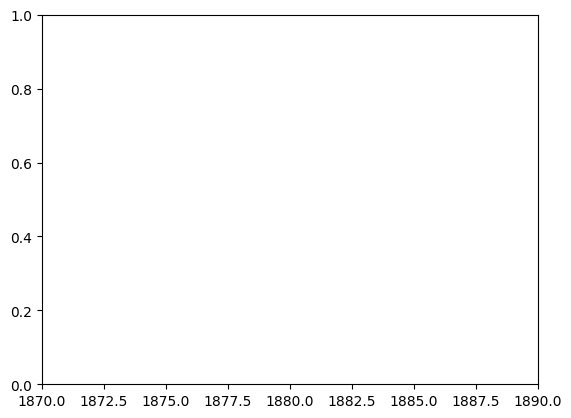

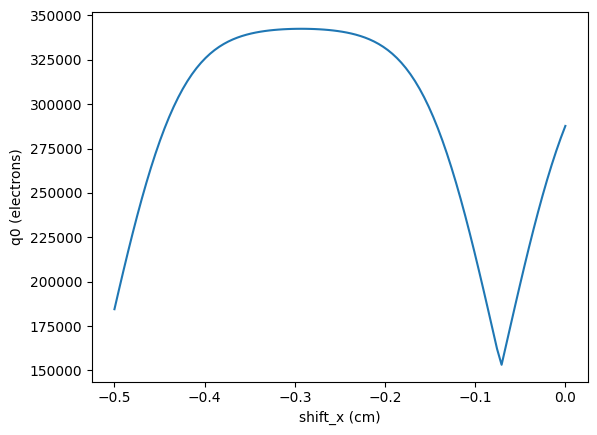

In [7]:
# --- Generate Target (Data) ---

from larndsim.fee_jax import get_average_hit_values

rngkey = 42

# Run stochastic simulation to get 'fake data'

q0_values = []
t0_values = []
# shifts = np.linspace(-0.07121, -0.0712, 100)
# shifts = np.linspace(-0.07121, -0.071207, 2)
shifts = np.linspace(-0.5, 0, 100)

for shift_x in shifts:
    p = current_params.replace(shift_x=shift_x, number_pix_neighbors=0, nb_tran_diff_bins=31)
    target_output = pred_strategy.predict(p, tracks, track_fields, rngkey)
    avg_t, avg_q, prob = get_average_hit_values(jnp.exp(target_output['ticks_prob']), target_output['adcs_distrib'])
    # q0 = target_output['adcs'][0]
    q0 = avg_q[-1][0]
    t0 = avg_t[-1][0]
    target_output['pixel_id'] = target_output['unique_pixels']
    # print(target_output['pixel_id'][-1])
    # q0_values.append(q0)
    q0_values.append(target_output['wfs'][-1].cumsum()[1878])
    t0_values.append(t0)
    # print(target_output['wfs'].shape)
    # plt.plot(target_output['wfs'][-1].cumsum()*0.1)
plt.xlim(1870, 1890)
plt.figure()
plt.plot(shifts, q0_values)
# plt.gca().twinx().plot(shifts, t0_values, color='orange')
plt.xlabel('shift_x (cm)')
plt.ylabel('q0 (electrons)')


Array([[0.000000e+00, 0.000000e+00, 0.000000e+00, ..., 0.000000e+00,
        0.000000e+00, 0.000000e+00],
       [0.000000e+00, 0.000000e+00, 0.000000e+00, ..., 0.000000e+00,
        0.000000e+00, 0.000000e+00],
       [0.000000e+00, 0.000000e+00, 0.000000e+00, ..., 0.000000e+00,
        0.000000e+00, 0.000000e+00],
       ...,
       [0.000000e+00, 0.000000e+00, 0.000000e+00, ..., 0.000000e+00,
        0.000000e+00, 0.000000e+00],
       [0.000000e+00, 0.000000e+00, 0.000000e+00, ..., 0.000000e+00,
        0.000000e+00, 0.000000e+00],
       [1.000000e+00, 9.820703e-01, 7.797503e-06, ..., 0.000000e+00,
        0.000000e+00, 0.000000e+00]], dtype=float32)

In [33]:
# --- Boundary diagnostics: fractional position within pixel/bin ---
from larndsim.detsim_jax import get_bin_shifts
from larndsim.sim_jax import shift_tracks

def _frac_pos(params, tracks, fields):
    shifted = shift_tracks(params, tracks, fields)
    x_idx = fields.index('x')
    y_idx = fields.index('y')
    plane_idx = fields.index('pixel_plane')
    borders = jnp.take(params.tpc_borders, shifted[:, plane_idx].astype(int), axis=0)
    x_local = shifted[:, x_idx] - borders[:, 0, 0]
    y_local = shifted[:, y_idx] - borders[:, 1, 0]
    fx = (x_local / params.pixel_pitch) - jnp.floor(x_local / params.pixel_pitch)
    fy = (y_local / params.pixel_pitch) - jnp.floor(y_local / params.pixel_pitch)
    bins = get_bin_shifts(params, shifted, fields)
    return fx, fy, bins

for shift_x in shifts:
    p = current_params.replace(shift_x=shift_x, number_pix_neighbors=0)
    fx, fy, bins = _frac_pos(p, tracks, track_fields)
    print('shift_x', float(shift_x), 'fx', float(fx[0]), 'fy', float(fy[0]), 'bins', bins[0])

shift_x -0.07121 fx 1.1444091796875e-05 fy 0.25521087646484375 bins [330 322]
shift_x -0.0712 fx 0.9999847412109375 fy 0.25521087646484375 bins [329 322]


In [85]:
q0_values

[Array(0., dtype=float32),
 Array(0., dtype=float32),
 Array(0., dtype=float32),
 Array(0., dtype=float32),
 Array(0., dtype=float32),
 Array(0., dtype=float32),
 Array(0., dtype=float32),
 Array(0., dtype=float32),
 Array(0., dtype=float32),
 Array(0., dtype=float32)]

In [76]:
target_output.keys()

dict_keys(['adcs', 'pixel_x', 'pixel_y', 'pixel_z', 'ticks', 'hit_prob', 'event', 'hit_pixels', 'unique_pixels', 'wfs', 'pixel_id'])

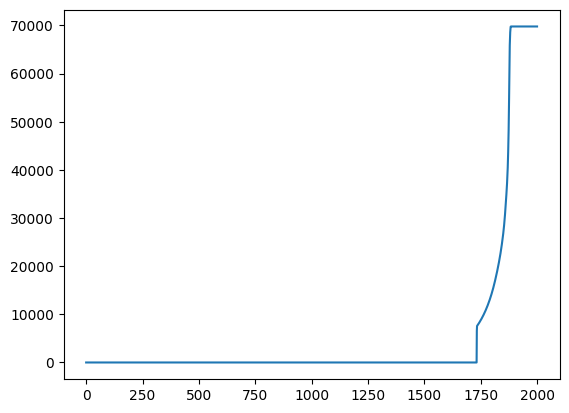